In [162]:
import numpy 
import networkx as nx
import pandas as pd

In [163]:
import math
from dataclasses import dataclass


NEG_INF = float("-inf")


def logl(x):
    return math.log(x)


def logsumexp(values):
    if not values:
        return NEG_INF

    m = max(values)

    if m == NEG_INF:
        return NEG_INF

    return m + math.log(sum(math.exp(v - m) for v in values))


@dataclass
class UResult:
    U: list
    flow_Us: list
    Cs: list


@dataclass
class LikelihoodResult:
    root_loglikelihood: float
    LL: list

In [164]:
def calculate_Us(
    birth_rates,
    death_rates,
    sampling_rates,
    transition_probabilities,
    transition_epochs,
):
    num_states = len(birth_rates)
    num_steps = len(transition_epochs)

    U = [[0.0 for _ in range(num_states)] for _ in range(num_steps)]
    flow_Us = [[0.0 for _ in range(num_states)] for _ in range(num_steps)]
    Cs = [[0.0 for _ in range(num_states)] for _ in range(num_steps)]

    # U[0,:] = 1 - rho
    for s in range(num_states):
        U[0][s] = 1.0 - sampling_rates[s]

        numerator = U[0][s] - death_rates[s] / birth_rates[s]
        denominator = U[0][s] - 1.0

        Cs[0][s] = numerator / denominator

    for n in range(1, num_steps):

        prev_time = transition_epochs[n - 1].time
        time = transition_epochs[n].time

        for s in range(num_states):

            delta = birth_rates[s] - death_rates[s]

            flow_Us[n][s] = (
                1.0
                - delta
                / (
                    birth_rates[s]
                    * (
                        1.0
                        - Cs[n - 1][s]
                        * math.exp(-delta * (time - prev_time))
                    )
                )
            )

        for s in range(num_states):

            U[n][s] = 0.0

            for next_s in range(num_states):
                U[n][s] += (
                    transition_probabilities[s][next_s]
                    * flow_Us[n][next_s]
                )

            numerator = U[n][s] - death_rates[s] / birth_rates[s]
            denominator = U[n][s] - 1.0

            Cs[n][s] = numerator / denominator

    return UResult(U=U, flow_Us=flow_Us, Cs=Cs)

In [165]:
def calculate_log_likelihood_closed(
    tree,
    birth_rates,
    death_rates,
    transition_probabilities,
    sampling_rates,
    Cs,
    transition_epochs,
):

    num_states = len(birth_rates)
    num_steps = len(transition_epochs)

    num_edges = len(tree.edges)

    LL = [
        [NEG_INF for _ in range(num_states)]
        for _ in range(num_edges)
    ]

    # Bottom-up traversal
    for node_id in tree.postorder:

        v_node = tree.nodes[node_id]

        if v_node.parent == -1:
            continue

        edge_idx = v_node.edge_idx_to_parent

        u = v_node.parent
        v = node_id

        parent_node = tree.nodes[u]

        parent_time = parent_node.time
        child_time = v_node.time

        ############################################################
        # Boundary condition
        ############################################################

        boundary_condition = [NEG_INF] * num_states

        if len(v_node.children) == 0:

            child_state = v_node.state
            boundary_condition[child_state] = logl(
                sampling_rates[child_state]
            )

        elif len(v_node.children) == 2:

            left_child = v_node.children[0]
            right_child = v_node.children[1]

            left_edge_idx = tree.nodes[
                left_child
            ].edge_idx_to_parent

            right_edge_idx = tree.nodes[
                right_child
            ].edge_idx_to_parent

            for s in range(num_states):

                boundary_condition[s] = (
                    logl(birth_rates[s])
                    + LL[left_edge_idx][s]
                    + LL[right_edge_idx][s]
                )

        else:
            raise RuntimeError(
                "Expected 0 or 2 children."
            )

        ############################################################
        # Integrate upward
        ############################################################

        previous_LL = boundary_condition.copy()
        previous_time = child_time
        closest_n = 0

        current_LL = [0.0] * num_states

        for n in range(1, num_steps):

            time = transition_epochs[n].time
            prev_transition_time = transition_epochs[n - 1].time

            if parent_time > time:
                closest_n = n

            if parent_time > time and time > child_time:

                ####################################################
                # Continuous flow
                ####################################################

                for s in range(num_states):

                    delta = (
                        birth_rates[s]
                        - death_rates[s]
                    )

                    flow = (
                        -delta
                        * (time - previous_time)
                        + 2.0
                        * (
                            math.log(
                                1.0
                                - Cs[n - 1][s]
                                * math.exp(
                                    -delta
                                    * (
                                        previous_time
                                        - prev_transition_time
                                    )
                                )
                            )
                            - math.log(
                                1.0
                                - Cs[n - 1][s]
                                * math.exp(
                                    -delta
                                    * (
                                        time
                                        - prev_transition_time
                                    )
                                )
                            )
                        )
                    )

                    previous_LL[s] += flow

                ####################################################
                # Discrete transition
                ####################################################

                for s in range(num_states):

                    terms = []

                    for next_s in range(num_states):

                        p = transition_probabilities[s][next_s]

                        if p > 0.0:

                            terms.append(
                                previous_LL[next_s]
                                + logl(p)
                            )

                    current_LL[s] = logsumexp(terms)

                previous_LL, current_LL = (
                    current_LL,
                    previous_LL,
                )

                previous_time = time

        ############################################################
        # Final propagation
        ############################################################

        if parent_time > previous_time:

            n = closest_n

            for s in range(num_states):

                delta = (
                    birth_rates[s]
                    - death_rates[s]
                )

                

                flow = (
                    -delta
                    * (parent_time - previous_time)
                    + 2.0
                    * (
                        math.log(
                            1.0
                            - Cs[n][s]
                            * math.exp(
                                -delta
                                * (
                                    previous_time
                                    - transition_epochs[n].time
                                )
                            )
                        )
                        - math.log(
                            1.0
                            - Cs[n][s]
                            * math.exp(
                                -delta
                                * (
                                    parent_time
                                    - transition_epochs[n].time
                                )
                            )
                        )
                    )
                )

                previous_LL[s] += flow

        LL[edge_idx] = previous_LL.copy()

    ############################################################
    # Root likelihood
    ############################################################

    root_node = tree.nodes[tree.root]

    if len(root_node.children) != 1:
        raise RuntimeError(
            "Expected dummy root with one child."
        )

    child = root_node.children[0]
    root_edge = tree.nodes[child].edge_idx_to_parent

    return LikelihoodResult(
        root_loglikelihood=LL[root_edge][0],
        LL=LL,
    )

In [166]:
from dataclasses import dataclass


@dataclass
class LikelihoodNode:
    id: int
    parent: int
    children: list[int]

    state: int
    time: float

    edge_idx_to_parent: int


@dataclass
class PreparedTree:
    nodes: dict[int, LikelihoodNode]

    root: int

    edges: list[tuple[int, int]]

    postorder: list[int]

In [167]:
from dataclasses import dataclass, field


@dataclass
class LikelihoodNode:
    original_id: int = -1
    time: float = 0.0
    state: int = 0

    parent: int = -1
    children: list = field(default_factory=list)

    edge_idx_to_parent: int = -1


@dataclass
class PreparedTree:
    nodes: list = field(default_factory=list)
    edges: list = field(default_factory=list)

    root: int = -1
    postorder: list = field(default_factory=list)


from dataclasses import dataclass, field


@dataclass
class Node:
    id: int
    T: float
    is_leaf: int
    state: int


@dataclass
class Edge:
    u: int
    v: int
    length: float


@dataclass
class DiffTNode:
    state: int = -1
    diff_time: float = 0.0
    children: list = field(default_factory=list)


@dataclass
class TransitionEpoch:
    time: float
    transition_edges: list

In [168]:
def build_postorder(v, nodes, postorder):

    for child in nodes[v].children:
        build_postorder(
            child,
            nodes,
            postorder
        )

    postorder.append(v)

In [169]:
def prepare_tree(
    input_nodes,
    input_edges,
):

    tree = PreparedTree()

    n = len(input_nodes)

    ####################################################
    # Original id -> contiguous index
    ####################################################

    id_to_idx = {}

    for i, node in enumerate(input_nodes):
        id_to_idx[node.id] = i

    ####################################################
    # Nodes
    ####################################################

    tree.nodes = [
        LikelihoodNode()
        for _ in range(n)
    ]

    for i in range(n):

        tree.nodes[i].original_id = input_nodes[i].id
        tree.nodes[i].time = input_nodes[i].T
        tree.nodes[i].state = input_nodes[i].state

    ####################################################
    # Edges
    ####################################################

    indegree = [0] * n

    for edge_idx, e in enumerate(input_edges):

        if e.u not in id_to_idx:
            raise RuntimeError(
                "Unknown node id in edge.u"
            )

        if e.v not in id_to_idx:
            raise RuntimeError(
                "Unknown node id in edge.v"
            )

        parent = id_to_idx[e.u]
        child = id_to_idx[e.v]

        tree.edges.append(
            (parent, child)
        )

        tree.nodes[parent].children.append(
            child
        )

        tree.nodes[child].parent = parent

        tree.nodes[
            child
        ].edge_idx_to_parent = edge_idx

        indegree[child] += 1

    ####################################################
    # Root
    ####################################################

    root = -1

    for i in range(n):

        if indegree[i] == 0:

            if root != -1:
                raise RuntimeError(
                    "Multiple roots detected."
                )

            root = i

    if root == -1:
        raise RuntimeError(
            "No root found."
        )

    tree.root = root

    ####################################################
    # Postorder traversal
    ####################################################

    build_postorder(
        tree.root,
        tree.nodes,
        tree.postorder
    )

    return tree

In [170]:
import csv


def load_nodes(file):

    print("LOADING NODES ...")

    nodes = []

    try:
        with open(file, newline="") as f:

            reader = csv.reader(f)

            try:
                next(reader)  # skip header
            except StopIteration:
                raise RuntimeError(
                    f"File is empty or missing header: {file}"
                )

            for row in reader:

                if len(row) < 4:
                    raise RuntimeError(
                        f"Malformed row in {file}"
                    )

                n = Node(
                    id=int(row[0]),
                    T=float(row[1]),
                    is_leaf=int(row[2]),
                    state=int(row[3]),
                )

                nodes.append(n)

    except FileNotFoundError:
        raise RuntimeError(
            f"Failed to open file: {file}"
        )

    print(f"LOADED {len(nodes)} NODES")

    return nodes

In [171]:
import csv


def load_edges(file):

    print("LOADING EDGES ...")

    edges = []

    try:
        with open(file, newline="") as f:

            reader = csv.reader(f)

            try:
                next(reader)  # skip header
            except StopIteration:
                raise RuntimeError(
                    f"File is empty or missing header: {file}"
                )

            for row in reader:

                if len(row) < 3:
                    raise RuntimeError(
                        f"Malformed row in {file}"
                    )

                e = Edge(
                    u=int(row[0]),
                    v=int(row[1]),
                    length=float(row[2]),
                )

                edges.append(e)

    except FileNotFoundError:
        raise RuntimeError(
            f"Failed to open file: {file}"
        )

    print(f"LOADED {len(edges)} EDGES")

    return edges

In [173]:
num_trees = 25
directory = "../data/simulation/bdt_ctmc/test6_multi"


In [174]:
import os


trees = []

for i in range(num_trees):

    node_path = os.path.join(
        directory,
        f"nodes_{i}.csv"
    )

    edge_path = os.path.join(
        directory,
        f"edges_{i}.csv"
    )

    loaded_nodes = load_nodes(node_path)
    loaded_edges = load_edges(edge_path)

    if len(loaded_nodes) == 0:
        raise RuntimeError("No nodes loaded")

    if len(loaded_edges) == 0:
        raise RuntimeError("No edges loaded")

    tree = prepare_tree(
        loaded_nodes,
        loaded_edges,
    )

    trees.append(tree)

LOADING NODES ...
LOADED 764 NODES
LOADING EDGES ...
LOADED 763 EDGES
LOADING NODES ...
LOADED 6664 NODES
LOADING EDGES ...
LOADED 6663 EDGES
LOADING NODES ...
LOADED 96 NODES
LOADING EDGES ...
LOADED 95 EDGES
LOADING NODES ...
LOADED 5226 NODES
LOADING EDGES ...
LOADED 5225 EDGES
LOADING NODES ...
LOADED 2054 NODES
LOADING EDGES ...
LOADED 2053 EDGES
LOADING NODES ...
LOADED 270 NODES
LOADING EDGES ...
LOADED 269 EDGES
LOADING NODES ...
LOADED 1612 NODES
LOADING EDGES ...
LOADED 1611 EDGES
LOADING NODES ...
LOADED 11928 NODES
LOADING EDGES ...
LOADED 11927 EDGES
LOADING NODES ...
LOADED 1160 NODES
LOADING EDGES ...
LOADED 1159 EDGES
LOADING NODES ...
LOADED 1092 NODES
LOADING EDGES ...
LOADED 1091 EDGES
LOADING NODES ...
LOADED 1056 NODES
LOADING EDGES ...
LOADED 1055 EDGES
LOADING NODES ...
LOADED 3742 NODES
LOADING EDGES ...
LOADED 3741 EDGES
LOADING NODES ...
LOADED 7622 NODES
LOADING EDGES ...
LOADED 7621 EDGES
LOADING NODES ...
LOADED 4208 NODES
LOADING EDGES ...
LOADED 4207 EDGE

In [ ]:
birth_rates = [9.0, 8.0, 7.0]
death_rates = [0.2, 0.7, 0.5]
sampling_rates = [0.5, 0.4, 0.6]
transition_probabilities = [[0.2,  0.35, 0.45], [0, 1, 0], [0, 0, 1]]
free_edges = [(0, 1), (0, 2)]

transition_epochs = [
    TransitionEpoch(0.0, []),
    TransitionEpoch(0.6, free_edges)
]


LL = 0.0

u_result = calculate_Us(
    birth_rates=birth_rates,
    death_rates=death_rates,
    sampling_rates=sampling_rates,
    transition_probabilities=transition_probabilities,
    transition_epochs=transition_epochs,
)

for tree in trees:

    result = calculate_log_likelihood_closed(
        tree=tree,
        birth_rates=birth_rates,
        death_rates=death_rates,
        transition_probabilities=transition_probabilities,
        sampling_rates=sampling_rates,
        Cs=u_result.Cs,
        transition_epochs=transition_epochs,
    )
    LL += result.root_loglikelihood


print(LL)

24149.892345066386


## Likelihood plots (a)

In [121]:
import numpy as np

In [128]:
gran = 5

In [129]:
LL_map = np.zeros((15 * gran, 15 * gran))

In [141]:
for i in range(15 * gran):
    for j in range(15 * gran):

        if i < j: continue

        
        birth_rates = [8.0, i / gran + 1e-6]
        death_rates = [0.0, j / gran]
        sampling_rates = [0.5, 0.6]
        transition_probabilities = [[0.2,  0.8], [0, 1]]
        free_edges = [(0, 1)]

        transition_epochs = [
            TransitionEpoch(0.0, []),
            TransitionEpoch(0.6, free_edges)
        ]


        LL = 0.0

        for tree in trees:

            u_result = calculate_Us(
                birth_rates=birth_rates,
                death_rates=death_rates,
                sampling_rates=sampling_rates,
                transition_probabilities=transition_probabilities,
                transition_epochs=transition_epochs,
            )

            result = calculate_log_likelihood_closed(
                tree=tree,
                birth_rates=birth_rates,
                death_rates=death_rates,
                transition_probabilities=transition_probabilities,
                sampling_rates=sampling_rates,
                Cs=u_result.Cs,
                transition_epochs=transition_epochs,
            )
            LL += result.root_loglikelihood

        print(i, j, birth_rates, death_rates, LL)
        

        LL_map[i, j] = LL

0 0 [8.0, 1e-06] [0.0, 0.0] -247998.9112351552
1 0 [8.0, 0.200001] [0.0, 0.0] -32851.054088781915
1 1 [8.0, 0.200001] [0.0, 0.2] -33433.32009616449
2 0 [8.0, 0.400001] [0.0, 0.0] -20797.404243994795
2 1 [8.0, 0.400001] [0.0, 0.2] -21357.040741031302
2 2 [8.0, 0.400001] [0.0, 0.4] -21921.071866350227
3 0 [8.0, 0.600001] [0.0, 0.0] -13835.317249944374
3 1 [8.0, 0.600001] [0.0, 0.2] -14372.359364915965
3 2 [8.0, 0.600001] [0.0, 0.4] -14914.530828588093
3 3 [8.0, 0.600001] [0.0, 0.6] -15461.684515191992
4 0 [8.0, 0.8000010000000001] [0.0, 0.0] -8967.519552147374
4 1 [8.0, 0.8000010000000001] [0.0, 0.2] -9482.065446762155
4 2 [8.0, 0.8000010000000001] [0.0, 0.4] -10002.40932688073
4 3 [8.0, 0.8000010000000001] [0.0, 0.6] -10528.396866711431
4 4 [8.0, 0.8000010000000001] [0.0, 0.8] -11059.867168260736
5 0 [8.0, 1.000001] [0.0, 0.0] -5254.362770584771
5 1 [8.0, 1.000001] [0.0, 0.2] -5746.569047502181
5 2 [8.0, 1.000001] [0.0, 0.4] -6245.17559520272
5 3 [8.0, 1.000001] [0.0, 0.6] -6750.0266534

In [144]:
import matplotlib.pyplot as plt

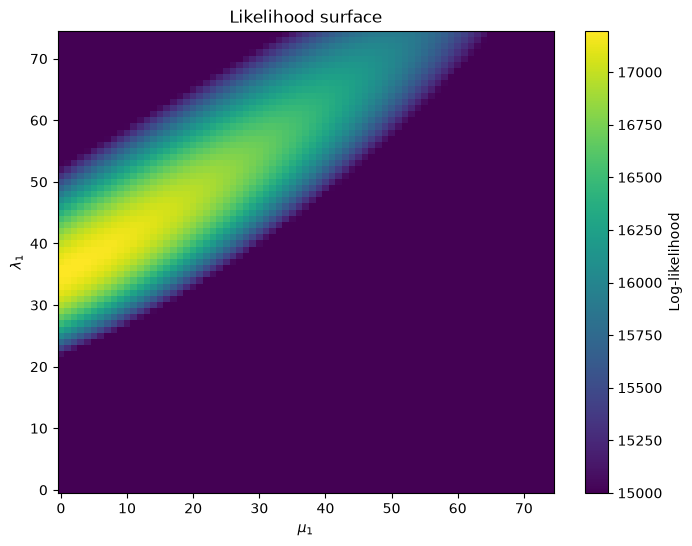

In [149]:
plt.figure(figsize=(8, 6))

im = plt.imshow(
    LL_map,
    origin="lower",
    # extent=[
    #     lambda0_grid.min(),
    #     lambda0_grid.max(),
    #     lambda1_grid.min(),
    #     lambda1_grid.max(),
    # ],
    aspect="auto",
    vmin=15000,
    vmax=LL_map.max(),
)

plt.colorbar(im, label="Log-likelihood")

plt.xlabel(r"$\mu_1$")
plt.ylabel(r"$\lambda_1$")
plt.title("Likelihood surface")

plt.show()

In [150]:
LL_map = np.zeros((15 * gran, 15 * gran))

In [151]:
for i in range(15 * gran):
    for j in range(15 * gran):

        if i < j: continue

        
        birth_rates = [i / gran + 1e-6, 7.0]
        death_rates = [j / gran, 0.0]
        sampling_rates = [0.5, 0.6]
        transition_probabilities = [[0.2,  0.8], [0, 1]]
        free_edges = [(0, 1)]

        transition_epochs = [
            TransitionEpoch(0.0, []),
            TransitionEpoch(0.6, free_edges)
        ]


        LL = 0.0

        for tree in trees:

            u_result = calculate_Us(
                birth_rates=birth_rates,
                death_rates=death_rates,
                sampling_rates=sampling_rates,
                transition_probabilities=transition_probabilities,
                transition_epochs=transition_epochs,
            )

            result = calculate_log_likelihood_closed(
                tree=tree,
                birth_rates=birth_rates,
                death_rates=death_rates,
                transition_probabilities=transition_probabilities,
                sampling_rates=sampling_rates,
                Cs=u_result.Cs,
                transition_epochs=transition_epochs,
            )
            LL += result.root_loglikelihood

        print(i, j, birth_rates, death_rates, LL)
        

        LL_map[i, j] = LL

0 0 [1e-06, 7.0] [0.0, 0.0] -76614.64792737724
1 0 [0.200001, 7.0] [0.0, 0.0] -1646.6016132450056
1 1 [0.200001, 7.0] [0.2, 0.0] -1844.1693998146918
2 0 [0.400001, 7.0] [0.0, 0.0] 2591.7654503825506
2 1 [0.400001, 7.0] [0.2, 0.0] 2400.4165761352106
2 2 [0.400001, 7.0] [0.4, 0.0] 2208.46503792861
3 0 [0.600001, 7.0] [0.0, 0.0] 5057.233553993883
3 1 [0.600001, 7.0] [0.2, 0.0] 4872.193474399716
3 2 [0.600001, 7.0] [0.4, 0.0] 4686.269484414048
3 3 [0.600001, 7.0] [0.6, 0.0] 4499.514253886428
4 0 [0.8000010000000001, 7.0] [0.0, 0.0] 6793.557730241285
4 1 [0.8000010000000001, 7.0] [0.2, 0.0] 6614.8920798657155
4 2 [0.8000010000000001, 7.0] [0.4, 0.0] 6435.078251711116
4 3 [0.8000010000000001, 7.0] [0.6, 0.0] 6254.179396483964
4 4 [0.8000010000000001, 7.0] [0.8, 0.0] 6072.255529532133
5 0 [1.000001, 7.0] [0.0, 0.0] 8127.907877340316
5 1 [1.000001, 7.0] [0.2, 0.0] 7955.658274450209
5 2 [1.000001, 7.0] [0.4, 0.0] 7782.015233621888
5 3 [1.000001, 7.0] [0.6, 0.0] 7607.048973512001
5 4 [1.000001, 

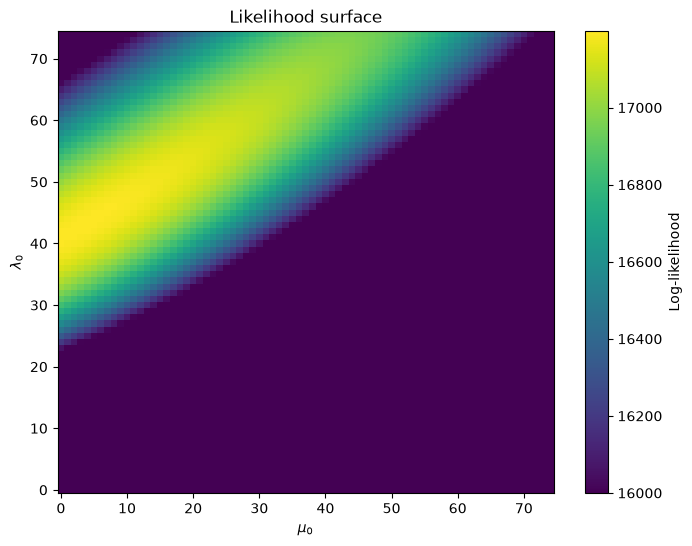

In [153]:
plt.figure(figsize=(8, 6))

im = plt.imshow(
    LL_map,
    origin="lower",
    # extent=[
    #     lambda0_grid.min(),
    #     lambda0_grid.max(),
    #     lambda1_grid.min(),
    #     lambda1_grid.max(),
    # ],
    aspect="auto",
    vmin=16000,
    vmax=LL_map.max(),
)

plt.colorbar(im, label="Log-likelihood")

plt.xlabel(r"$\mu_0$")
plt.ylabel(r"$\lambda_0$")
plt.title("Likelihood surface")

plt.show()

## Likelihood plots (b)

In [176]:
gran = 20
K_map = np.zeros(15 * gran)

In [240]:
for i in range(15 * gran):
    orig_sample_b = 0.4
    orig_birth_b = 8.0
    orig_death_b = 0.7
    orig_trans_b = 0.35

    orig_sample_c = 0.6
    orig_birth_c = 7.0
    orig_death_c = 0.5
    orig_trans_c = 0.45

    birth_b = i / gran + 8.0 - 0.7 + 1e-10
    death_b = birth_b - (orig_birth_b - orig_death_b)
    sampling_b = (orig_birth_b * orig_sample_b) / birth_b
    trans_b = (orig_trans_b * orig_sample_b) / sampling_b             # = c_b_target * birth_b / b_b_target

    trans_c = 1 - 0.2 - trans_b
    sampling_c = (orig_trans_c * orig_sample_c) / trans_c
    birth_c = (orig_birth_c * orig_sample_c) / sampling_c
    death_c = birth_c - (orig_birth_c - orig_death_c)

    print(birth_b, death_b, sampling_b, trans_b)
    print(birth_c, death_c, sampling_c, trans_c)

    if death_b < 0: continue
    if death_c < 0: continue
    
    
    birth_rates = [9.0, birth_b, birth_c]
    death_rates = [0.2, death_b, death_c]
    sampling_rates = [0.5, sampling_b, sampling_c]
    transition_probabilities = [[1 - trans_b - trans_c,  trans_b, trans_c], [0, 1, 0], [0, 0, 1]]
    free_edges = [(0, 1), (1, 2)]

    transition_epochs = [
        TransitionEpoch(0.0, []),
        TransitionEpoch(0.6, free_edges)
    ]


    LL = 0.0

    u_result = calculate_Us(
        birth_rates=birth_rates,
        death_rates=death_rates,
        sampling_rates=sampling_rates,
        transition_probabilities=transition_probabilities,
        transition_epochs=transition_epochs,
    )

    for tree in trees:

        result = calculate_log_likelihood_closed(
            tree=tree,
            birth_rates=birth_rates,
            death_rates=death_rates,
            transition_probabilities=transition_probabilities,
            sampling_rates=sampling_rates,
            Cs=u_result.Cs,
            transition_epochs=transition_epochs,
        )
        LL += result.root_loglikelihood

    print(i, birth_rates, death_rates, sampling_rates, transition_probabilities)
    print(LL)
    print()
    

    K_map[i] = LL

7.3000000001 1.000000082740371e-10 0.4383561643775568 0.3193750000043749
7.476388888820836 0.9763888888208356 0.5617685305642812 0.48062499999562514
0 [9.0, 7.3000000001, 7.476388888820836] [0.2, 1.000000082740371e-10, 0.9763888888208356] [0.5, 0.4383561643775568, 0.5617685305642812] [[0.19999999999999996, 0.3193750000043749, 0.48062499999562514], [0, 1, 0], [0, 0, 1]]
24149.892345066375

7.3500000001000005 0.05000000010000072 0.4353741496539405 0.321562500004375
7.442361111043056 0.9423611110430556 0.5643370346230573 0.47843749999562507
1 [9.0, 7.3500000001000005, 7.442361111043056] [0.2, 0.05000000010000072, 0.9423611110430556] [0.5, 0.4353741496539405, 0.5643370346230573] [[0.2, 0.321562500004375, 0.47843749999562507], [0, 1, 0], [0, 0, 1]]
24149.892345066386

7.4000000000999995 0.10000000009999965 0.4324324324265888 0.3237500000043749
7.408333333265279 0.9083333332652792 0.5669291338634757 0.4762499999956251
2 [9.0, 7.4000000000999995, 7.408333333265279] [0.2, 0.10000000009999965, 

(24140.0, 24155.0)

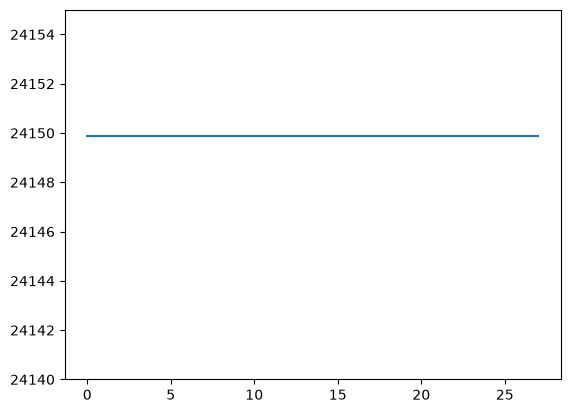

In [241]:
plt.plot(K_map[:28])
plt.ylim([24140, 24155])

In [194]:
gran = 20
K_map = np.zeros(15 * gran)

In [229]:
for i in range(15 * gran):
    orig_sample_a = 0.5
    orig_birth_a = 9.0
    orig_death_a = 0.2
    orig_trans_a = 0.2

    orig_sample_c = 0.6
    orig_birth_c = 7.0
    orig_death_c = 0.5
    orig_trans_c = 0.45

    birth_a = i / gran + 9.0 - 0.2 + 1e-10
    death_a = birth_a - (orig_birth_a - orig_death_a)
    sampling_a = (orig_birth_a * orig_sample_a) / birth_a
    trans_a = (orig_trans_a * orig_sample_a) / sampling_a             # = c_b_target * birth_b / b_b_target

    trans_c = 1 - 0.35 - trans_a
    sampling_c = (orig_trans_c * orig_sample_c) / trans_c
    birth_c = (orig_birth_c * orig_sample_c) / sampling_c
    death_c = birth_c - (orig_birth_c - orig_death_c)
        

    print(birth_a, death_a, sampling_a, trans_a)
    print(birth_c, death_c, sampling_c, trans_c)

    if death_a < 0: continue
    if death_c < 0: continue
    
    
    birth_rates = [birth_a, 8.0, birth_c]
    death_rates = [death_a, 0.7, death_c]
    sampling_rates = [sampling_a, 0.4, sampling_c]
    transition_probabilities = [[trans_a,  1 - trans_a - trans_c, trans_c], [0, 1, 0], [0, 0, 1]]
    free_edges = [(0, 1), (1, 2)]

    transition_epochs = [
        TransitionEpoch(0.0, []),
        TransitionEpoch(0.6, free_edges)
    ]


    LL = 0.0

    u_result = calculate_Us(
        birth_rates=birth_rates,
        death_rates=death_rates,
        sampling_rates=sampling_rates,
        transition_probabilities=transition_probabilities,
        transition_epochs=transition_epochs,
    )

    for tree in trees:

        result = calculate_log_likelihood_closed(
            tree=tree,
            birth_rates=birth_rates,
            death_rates=death_rates,
            transition_probabilities=transition_probabilities,
            sampling_rates=sampling_rates,
            Cs=u_result.Cs,
            transition_epochs=transition_epochs,
        )
        LL += result.root_loglikelihood

    print(i, birth_rates, death_rates, sampling_rates, transition_probabilities)
    print(LL)
    print()
    

    K_map[i] = LL

8.8000000001 1.000000082740371e-10 0.5113636363578253 0.19555555555777782
7.069135802434567 0.569135802434567 0.5941320293427587 0.4544444444422222
0 [8.8000000001, 8.0, 7.069135802434567] [1.000000082740371e-10, 0.7, 0.569135802434567] [0.5113636363578253, 0.4, 0.5941320293427587] [[0.19555555555777782, 0.35, 0.4544444444422222], [0, 1, 0], [0, 0, 1]]
24150.677289132498

8.850000000100001 0.05000000010000072 0.5084745762654409 0.19666666666888893
7.051851851817283 0.5518518518172826 0.5955882352970373 0.4533333333311111
1 [8.850000000100001, 8.0, 7.051851851817283] [0.05000000010000072, 0.7, 0.5518518518172826] [0.5084745762654409, 0.4, 0.5955882352970373] [[0.19666666666888893, 0.3499999999999999, 0.4533333333311111], [0, 1, 0], [0, 0, 1]]
24150.490429813766

8.9000000001 0.10000000009999965 0.5056179775224088 0.19777777778000002
7.034567901199999 0.5345679011999991 0.597051597054531 0.45222222221999997
2 [8.9000000001, 8.0, 7.034567901199999] [0.10000000009999965, 0.7, 0.53456790119

(24140.0, 24155.0)

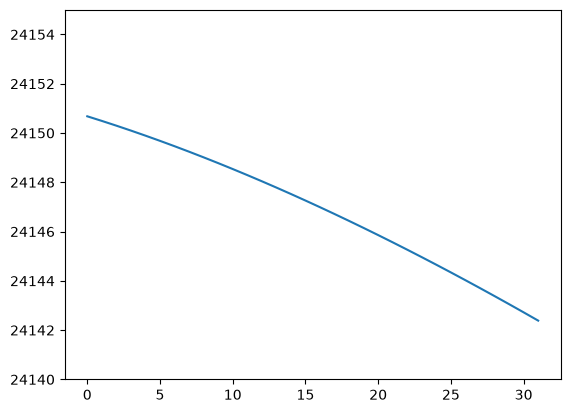

In [238]:
plt.plot(K_map[:32])
plt.ylim([24140, 24155])

In [215]:
birth_rates = [9.0, 8.0, 7.0]
death_rates = [0.2, 0.7, 0.5]
sampling_rates = [0.5, 0.4, 0.6]
transition_probabilities = [[0.2,  0.35, 0.45], [0, 1, 0], [0, 0, 1]]
free_edges = [(0, 1), (0, 2)]

transition_epochs = [
    TransitionEpoch(0.0, []),
    TransitionEpoch(0.6, free_edges)
]


LL = 0.0

u_result = calculate_Us(
    birth_rates=birth_rates,
    death_rates=death_rates,
    sampling_rates=sampling_rates,
    transition_probabilities=transition_probabilities,
    transition_epochs=transition_epochs,
)

u_result.Cs


[[-0.9555555555555556, -1.2812499999999998, -0.5476190476190478],
 [-0.060249043468343984, -0.01604811573325151, -0.011084856267940419]]

In [217]:
print(8.0 - 0.5)
print(0.7 - 0.5)
print(0.4 * 8.0 / (8.0 - 0.5))
print(0.35 * 8.0 / (8.0 - 0.5))
print(1 - 0.2 - 0.35 / 8.0 * (8.0 - 0.5))
print(7.0 / 0.471875 * 0.45)
print(7.340277777777778 - 7.0 + 0.5)
print(0.6 * 7.340277777777778 / 7.0)

7.5
0.19999999999999996
0.4266666666666667
0.3733333333333333
0.47187500000000004
6.675496688741722
0.8402777777777777
0.6291666666666667


In [218]:
birth_rates = [9.0, 7.5, 7.340277777777778]
death_rates = [0.2, 0.2, 0.8402777777777777]
sampling_rates = [0.5, 0.4266666666666667, 0.572185]
transition_probabilities = [[0.2,  0.328125, 0.471875], [0, 1, 0], [0, 0, 1]]
free_edges = [(0, 1), (0, 2)]

transition_epochs = [
    TransitionEpoch(0.0, []),
    TransitionEpoch(0.6, free_edges)
]


LL = 0.0

u_result = calculate_Us(
    birth_rates=birth_rates,
    death_rates=death_rates,
    sampling_rates=sampling_rates,
    transition_probabilities=transition_probabilities,
    transition_epochs=transition_epochs,
)

u_result.Cs

[[-0.9555555555555556, -1.2812499999999998, -0.5476202119166607],
 [-0.060249054543344525, -0.016048115733251447, -0.011084879835549588]]